In [57]:
# Import Libraries

import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

In [ ]:
# Load the dataset

flights = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

In [59]:
# Create Dataset for Model 2

model2_cols = [
    "arr_delay",
    "season",
    "carrier",
    "scheduled_hour",
    "distance",
    "origin",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "pressure",
    "visib"

]


In [60]:
# Remove rows with missing values in the selected columns

model2_data = flights[model2_cols].dropna()

In [61]:
# Create Model 1 Comparison dataset from Model 2 sample

model1_comparison_data = model2_data[
    ['arr_delay', 'season', 'carrier', 'scheduled_hour', 'distance', 'origin']
].copy() 

In [62]:
# Check sample size after removing missing values
print(f"Sample size for Model 2: {len(model2_data)}")
print(f"Flights excluded:", len(flights) - len(model2_data))

Sample size for Model 2: 291140
Flights excluded: 36206


In [ ]:
# Check for missing values in the selected columns

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
arr_delay         0
season            0
carrier           0
scheduled_hour    0
distance          0
origin            0
temp              0
humid             0
wind_speed        0
precip            0
pressure          0
visib             0
dtype: int64


In [78]:
# Summary statistics for weather variables

weather_summary = model2_data[['temp', 'humid', 'wind_speed', 'precip', 'pressure', 'visib']].describe()

print("Summary statistics for weather variables:")
print(weather_summary)

Summary statistics for weather variables:
                temp          humid     wind_speed         precip  \
count  291140.000000  291140.000000  291140.000000  291140.000000   
mean       57.077140      56.148008      10.959332       0.001348   
std        18.079445      18.034573       5.484414       0.012589   
min        10.940000      12.740000       0.000000       0.000000   
25%        42.080000      42.320000       6.904680       0.000000   
50%        57.020000      54.350000      10.357020       0.000000   
75%        73.040000      69.320000      13.809360       0.000000   
max       100.040000     100.000000      39.126520       0.530000   

            pressure          visib  
count  291140.000000  291140.000000  
mean     1017.900041       9.587284  
std         7.419816       1.455421  
min       983.800000       0.000000  
25%      1012.900000      10.000000  
50%      1017.600000      10.000000  
75%      1022.900000      10.000000  
max      1042.100000      10.000

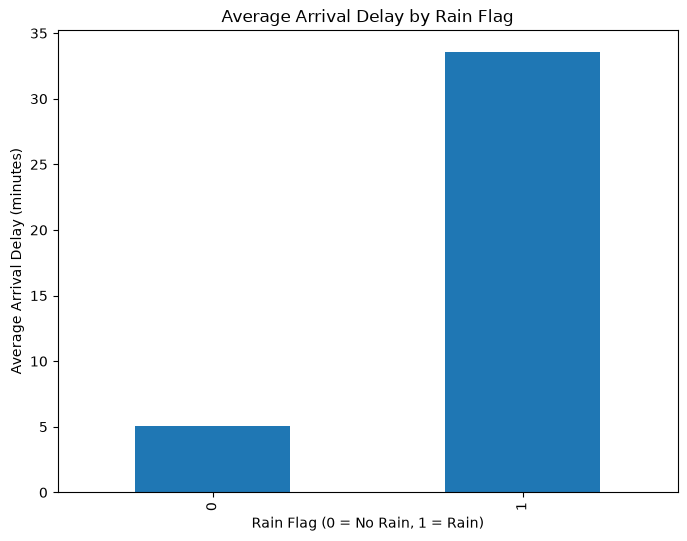

In [64]:
# Create a rain flag variable to indicate whether it rained or not

flights["rain_flag"] = (flights["precip"] > 0).astype(int)

# Calculate average arrival delay for flights with and without rain

rain_summary = flights.groupby("rain_flag").agg(
    avg_delay=("arr_delay", "mean")
)

# Create a bar chart

rain_summary.plot(
    kind="bar", legend=False, figsize=(8, 6), title="Average Arrival Delay by Rain Flag"
)

plt.title("Average Arrival Delay by Rain Flag")
plt.xlabel("Rain Flag (0 = No Rain, 1 = Rain)")
plt.ylabel("Average Arrival Delay (minutes)")
plt.show()

During periods of precipitation, flights had higher average arrival delays, sugguesting rain may contribute to longer delays and operational disruptions. 

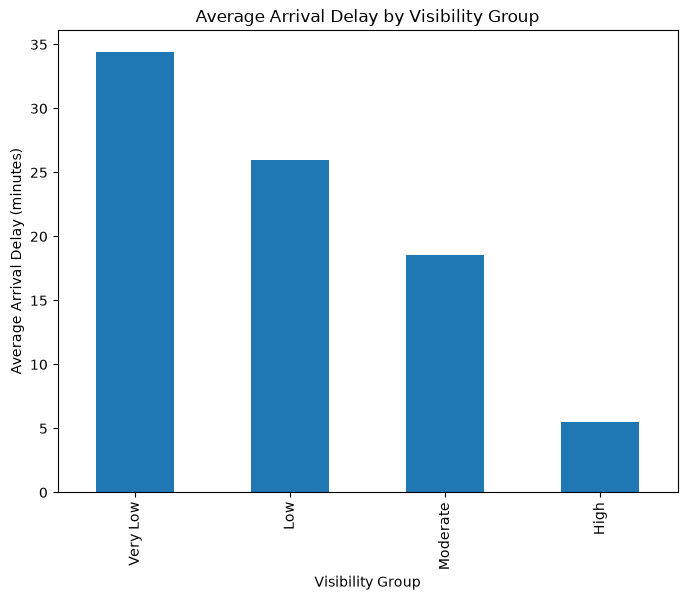

In [65]:

# Create a visibility group variable based on visibility ranges

flights["visibility_group"] = pd.cut(
    flights["visib"],
    bins=[-1, 1, 3, 5, 10, float("inf")],
    labels=["Very Low", "Low", "Moderate", "High", "Very High"]
)

# Calculate average arrival delay for each visibility group

visibility_summary = flights.groupby("visibility_group").agg(
    avg_delay=("arr_delay", "mean")
)

# Create a bar chart showing average arrival delay for each visibility group
visibility_summary.plot(
    kind="bar", legend=False, figsize=(8, 6)
)
plt.title("Average Arrival Delay by Visibility Group")
plt.xlabel("Visibility Group")
plt.ylabel("Average Arrival Delay (minutes)")
plt.show()  

Flights departing in lower visibility conditions generally expereince greater delays which sugguests reduced visibility may contribute to longer delays and operational challenges.

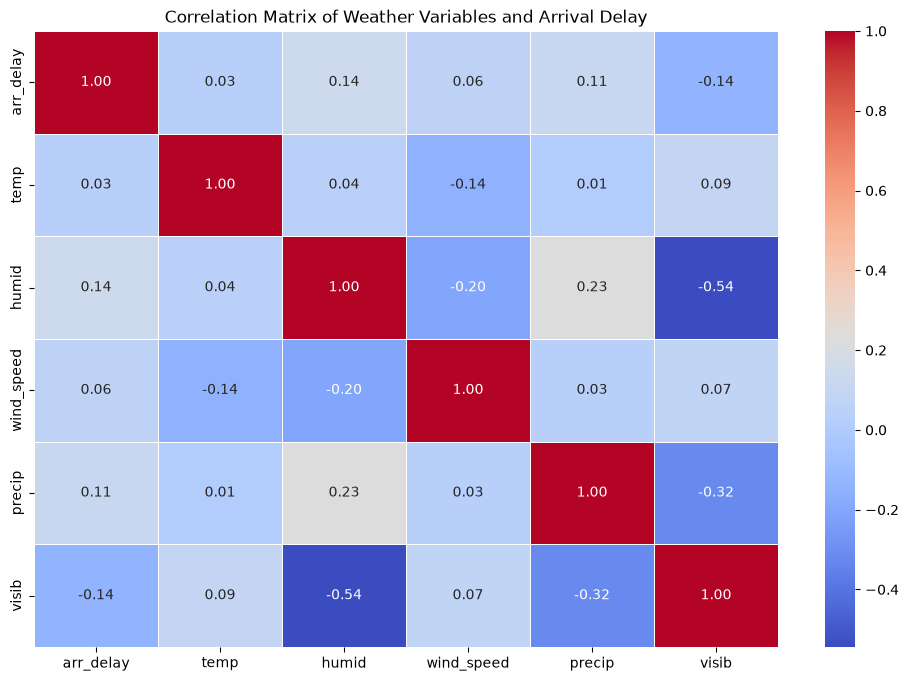

In [ ]:
# Select weather-related variables for correlation analysis

weather_vars = [
    "arr_delay",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "visib"
]

# Calculate correlation matrix

correlation_matrix = flights[weather_vars].corr()

# Display correlations with arrival delay
print("Correlations with Arrival Delay:")
print(correlation_matrix['arr_delay'].sort_values(ascending=False))

# Create a heatmap to visualize the correlation matrix

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Correlation Matrix of Weather Variables and Arrival Delay")
plt.show()  

Most individual correlations are relatively weak, suggesting weather conditions may be more informative when collectively evaluated through a regression model as opposed to through pairwise relationships alone. 

No missing values remain win the variables used for model 2 after removing incomplete observations.

In [67]:
# Create reference categories for the 'season' variable

model2_data['season'] = pd.Categorical(
model2_data['season'], 
categories=['Winter', 'Spring', 'Summer', 'Fall']
)

# create Reference categories for the airline variable

model2_data['carrier'] = pd.Categorical(
    model2_data['carrier'], 
    categories=[
        "AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA", "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"
    ]   
)

# Create reference categories for the airport variable

model2_data['origin'] = pd.Categorical(
    model2_data['origin'], 
    categories=["JFK", "LGA", "EWR"]
)


In [68]:
# Create Dummy Variables for Categorical Variables

model2_data = pd.get_dummies(model2_data, columns=['season', 'carrier', 'origin'], drop_first=True, dtype=int)

# Check resulting dataset

print("Shape of the dataset after creating dummy variables:", model2_data.shape)
print(model2_data.head())

Shape of the dataset after creating dummy variables: (291140, 29)
   arr_delay  scheduled_hour  distance   temp  humid  wind_speed  precip  \
0       11.0               5      1400  39.02  64.43    12.65858     0.0   
1       20.0               5      1416  39.92  54.81    14.96014     0.0   
2       33.0               5      1089  39.02  61.63    14.96014     0.0   
3      -18.0               5      1576  39.02  61.63    14.96014     0.0   
4      -25.0               6       762  39.92  54.81    16.11092     0.0   

   pressure  visib  season_Spring  ...  carrier_MQ  carrier_OO  carrier_UA  \
0    1011.9   10.0              0  ...           0           0           1   
1    1011.4   10.0              0  ...           0           0           1   
2    1012.1   10.0              0  ...           0           0           0   
3    1012.1   10.0              0  ...           0           0           0   
4    1011.7   10.0              0  ...           0           0           0   

   carri

Dummy variables created for season, airline, and airport with the first category in each group serving as the reference category.

In [69]:
# create the independent variables (X) and dependent variable (y)

y_model2 = model2_data['arr_delay']
X_model2 = model2_data.drop('arr_delay', axis=1)

# create intercept for the regression model

model2=sm.add_constant(X_model2)

# Fit the regression model

model2_fit = sm.OLS(y_model2, X_model2).fit()

# Results

print(model2_fit.summary())


                                 OLS Regression Results                                
Dep. Variable:              arr_delay   R-squared (uncentered):                   0.088
Model:                            OLS   Adj. R-squared (uncentered):              0.088
Method:                 Least Squares   F-statistic:                              999.5
Date:                Thu, 19 Nov 2026   Prob (F-statistic):                        0.00
Time:                        23:37:39   Log-Likelihood:                     -1.4895e+06
No. Observations:              291140   AIC:                                  2.979e+06
Df Residuals:                  291112   BIC:                                  2.979e+06
Df Model:                          28                                                  
Covariance Type:            nonrobust                                                  
                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------

Model 2 adds weather variables including temperature, humidity, wind speed, precipitation, atmospheric pressure, and visibility. 

In [70]:
# Calculate Variance Inflation Factor (VIF) for each independent variable

vif_data = pd.DataFrame()
vif_data['Variable'] = X_model2.columns
vif_data['VIF'] = [variance_inflation_factor(X_model2.values, i) for i in range(X_model2.shape[1])]
print(vif_data.sort_values('VIF', ascending=False).reset_index(drop=True))


          Variable         VIF
0         pressure  156.268741
1            visib   65.600508
2             temp   31.297078
3            humid   15.594718
4   scheduled_hour    9.893143
5    season_Summer    5.944336
6       wind_speed    5.692356
7         distance    5.133209
8       origin_EWR    4.149568
9       carrier_EV    3.507135
10      carrier_UA    3.490746
11     season_Fall    3.286623
12      carrier_B6    2.974608
13      origin_LGA    2.864554
14   season_Spring    2.743874
15      carrier_DL    2.498092
16      carrier_MQ    1.928764
17      carrier_9E    1.776000
18      carrier_US    1.737007
19      carrier_WN    1.448662
20      carrier_VX    1.227064
21          precip    1.170198
22      carrier_FL    1.125229
23      carrier_HA    1.049665
24      carrier_AS    1.044864
25      carrier_F9    1.026706
26      carrier_YV    1.025110
27      carrier_OO    1.001475


To assess multicolinearity among the predictors variance inflation factors (VIF) were calculated. VIF calues under 5 typically indicate multicollinearity is not a major concern. 

In [71]:
# Calculate heteroskedasticity-robust standard errors

model2_robust = model2_fit.get_robustcov_results(cov_type='HC3')

# Results

print(model2_robust.summary())

                                 OLS Regression Results                                
Dep. Variable:              arr_delay   R-squared (uncentered):                   0.088
Model:                            OLS   Adj. R-squared (uncentered):              0.088
Method:                 Least Squares   F-statistic:                              659.3
Date:                Thu, 19 Nov 2026   Prob (F-statistic):                        0.00
Time:                        23:37:49   Log-Likelihood:                     -1.4895e+06
No. Observations:              291140   AIC:                                  2.979e+06
Df Residuals:                  291112   BIC:                                  2.979e+06
Df Model:                          28                                                  
Covariance Type:                  HC3                                                  
                     coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------

In [72]:
# test for heteroskedasticity using Breusch-Pagan test

# Add an intercept because X_model2 was not passed through sm.add_constant()
bp_test = het_breuschpagan(model2_fit.resid, bp_exog)

print("LM Statistic:", bp_test[0])
print("p-value:", bp_test[1])

LM Statistic: 2846.5107063809855
p-value: 0.0


In order to evaluate whether the residual variance remains constant across observations, the Breusch-Pagan test is used. 

In [79]:
# Display weather coefficients only

weather_coeffs = model2_fit.params[['temp', 'humid', 'wind_speed', 'precip', 'pressure', 'visib']]
print("Weather Coefficients:")
print(weather_coeffs.sort_values(key=abs, ascending=False))


Weather Coefficients:
precip        82.322352
visib         -1.122563
wind_speed     0.568079
humid          0.273349
pressure      -0.032569
temp           0.005738
dtype: float64


Precipitation had the largest positive coefficient among the weather variables which indicated the strongest association with arrival delays. 

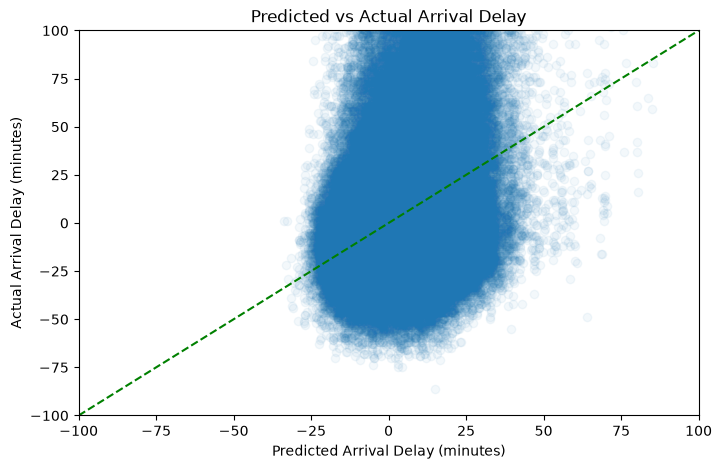

In [82]:
# Compare predicted and actual arrival delays

predicted = model2_fit.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(
    predicted,
    y_model2,
    alpha=0.05
)

plt.xlabel("Predicted Arrival Delay (minutes)")
plt.ylabel("Actual Arrival Delay (minutes)")
plt.title("Predicted vs Actual Arrival Delay")
plt.xlim(-100, 100)
plt.ylim(-100, 100)
plt.axline((0, 0), slope=1, color='Green', linestyle='--')

plt.show()

The model captures general delay patterns, however, substantial variation remains unexplained. 

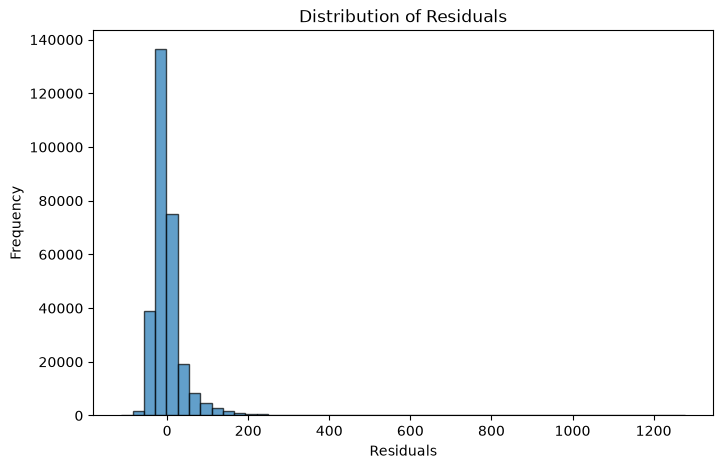

In [83]:
# Distribution of residuals

plt.figure(figsize=(8,5))

plt.hist(
    model2_fit.resid,
    bins=50,
    edgecolor='k',
    alpha=0.7
)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

The distribution of residuals is right skewed which sugguests unusually large delays are still difficult to explain with the variables included in the model.

In [73]:
# Set reference categories

model1_comparison_data["season"] = pd.Categorical(
    model1_comparison_data["season"],   
    categories=["Winter", "Spring", "Summer", "Fall"]   
)

model1_comparison_data["carrier"] = pd.Categorical(
    model1_comparison_data["carrier"],  
    categories = [
            "AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA", "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"
            ]   
)

model1_comparison_data["origin"] = pd.Categorical(
    model1_comparison_data["origin"],   
    categories=["JFK", "LGA", "EWR"]
)



In [74]:
# create dummy variables

model1_comparison_data = pd.get_dummies(model1_comparison_data, columns=['season', 'carrier', 'origin'], drop_first=True, dtype=int)

In [75]:
# Run Model 1 on the same sample as Model 2

y_model1 = model1_comparison_data['arr_delay']
X_model1 = model1_comparison_data.drop(
    columns=['arr_delay']
)
x_model1 = sm.add_constant(X_model1)

model1_comparison = sm.OLS(y_model1, x_model1).fit()



In [77]:
comparison = pd.DataFrame({
    "Metric": ["R-squared", "Adj. R-squared", "AIC", "BIC"],
    "Model 1": [
        round(model1_comparison.rsquared, 4),
        round(model1_comparison.rsquared_adj, 4),
        round(model1_comparison.aic, 4),
        round(model1_comparison.bic, 4)
    ],
    "Model 2": [
        round(model2_fit.rsquared, 4),
        round(model2_fit.rsquared_adj, 4),
        round(model2_fit.aic, 4),
        round(model2_fit.bic, 4)
    ]
})

print(comparison)

           Metric       Model 1       Model 2
0       R-squared  5.400000e-02  8.770000e-02
1  Adj. R-squared  5.390000e-02  8.760000e-02
2             AIC  2.985835e+06  2.978993e+06
3             BIC  2.986079e+06  2.979289e+06


Model 2 builds on model 1 through incorporating weather variables such as temperature, humidity, wind speed, precipitation, pressure, and visibility. The addition of thes variables resulted in R-squared increasing from 0.0540 to 0.077 and adjusted R-squared increasing from 0.0539 to 0.0876, meaning the models performanance imrpoved.

In [ ]:
print(model2_data.shape)